In [336]:
from selecao_e_preparacao import buildDataset, filterDataset
import matplotlib.pyplot as plt
import numpy as np

# EXPERIMENTO 1: DRONE SAUDÁVEL
Para este experimento, repete-se a utilização de um drone saudável. Ou seja, iremos usar a categoria f0. Porém, agora aplicando FFT no sinal, o levando para o domínio da frequência.
Segue abaixo a tabela com todas as especificações que utilizaremos para este experimento:

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F0_SV0_SP1_C1_R1.mat` | Saudável | 0 | 1 | 1 | 1 | 600.000 | 10.000 Hz | 60 s | Mesmas condições experimentais |

In [337]:
dataset = buildDataset()    # carrega todo o dataset

In [338]:
dataset_f0 = filterDataset( # filtra com base nos parâmetros definidos.
    dataset=dataset,
    condition=0,
    severity=0,
    speed=1,
    channel=1,
    recording=1,
)

In [339]:
#nesse bloco vamos criar uma função que automaticamente plota o dataset filtrado quando chamada.
# ela obviamente vai ser reutilizada a posteriori.

def plotDataset(filtered_dataset):

    figure, axis = plt.subplots(figsize=(12, 4))

    for record in filtered_dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        condition, severity, speed, channel, recording = record[3:8]
        label = (
            f"F{condition} SV{severity} SP{speed} "
            f"C{channel} R{recording}"
        )
        axis.plot(timestamp, acceleration, label=label)

    axis.set_title("Sinal de aceleração no domínio do tempo")
    axis.set_xlabel("Tempo (s)")
    axis.set_ylabel("Aceleração")

    axis.legend()

    axis.grid(True)
    figure.tight_layout()
    plt.show()

    return figure, axis



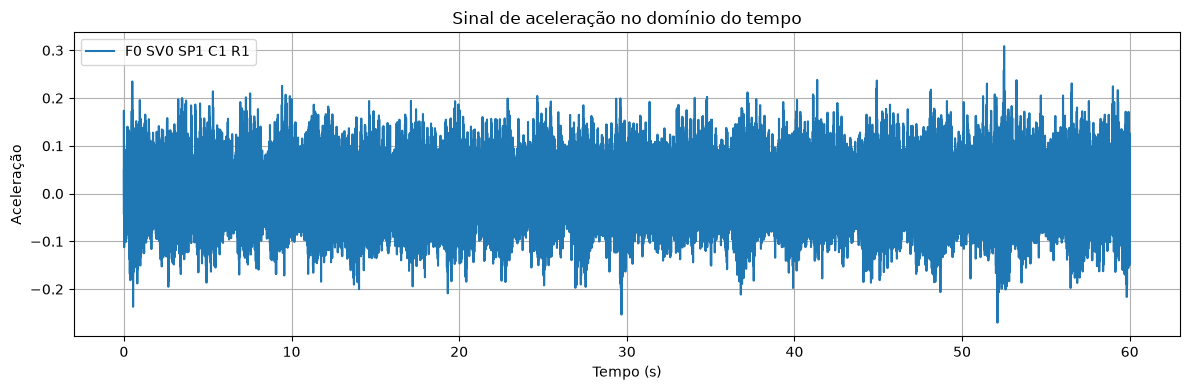

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [340]:
# agora vamos plotar o nosso sinal cujos parâmetros foram definidos na tabela:

plotDataset(dataset_f0)

In [341]:
# LKKKKKKKKKK ok talvez deveríamos usar uma escala de tempo menor para visualizar ...

def filterDatasetByTimeInterval(dataset, start_time, end_time):
    filtrado = []

    for record in dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        intervalo = (timestamp >= start_time) & (timestamp <= end_time)
        if not np.any(intervalo):
            continue

        samples = np.flatnonzero(intervalo)
        sample_1 = samples[0]
        sample_f = samples[-1] + 1

        filtrado_r = list(record)
        filtrado_r[0] = acceleration[sample_1:sample_f]
        filtrado_r[2] = timestamp[sample_1:sample_f]

        filtrado.append(filtrado_r)

    return filtrado

In [342]:
dataset_f0_small = filterDatasetByTimeInterval(dataset=dataset_f0,
                                               start_time=dataset_f0[0][2].min(),
                                               end_time=dataset_f0[0][2].min()+0.2)

Observamos acima o padrão típico das oscilações para hélices saudáveis.

Drone saudável (F0):
  Número de amostras: 2001
  Resolução: 4.998 Hz
  Nyquist: 5000.0 Hz

Drone com falha (F1):
  Número de amostras: 2001
  Resolução: 4.998 Hz
  Nyquist: 5000.0 Hz



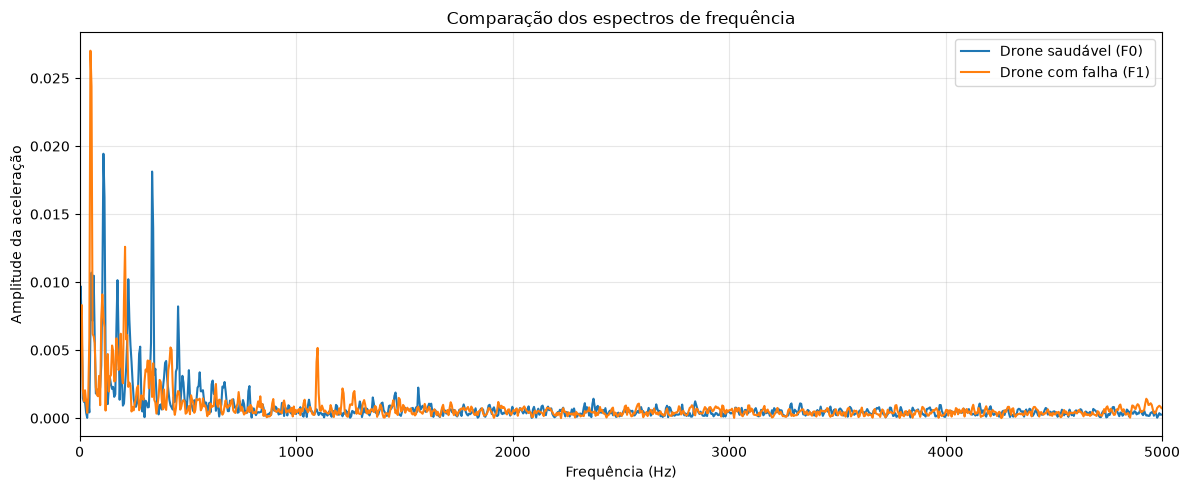

In [343]:
def plot_fft(datasets, fs=10000):
    plt.figure(figsize=(12, 4))

    for record in datasets:
        signal = np.asarray(record[0]).squeeze()

        N = len(signal)
        signal = signal - np.mean(signal)

        janela = np.hanning(N)
        fft = np.fft.rfft(signal * janela)
        frequencias = np.fft.rfftfreq(N, d=1/fs)
        amplitude = 2 * np.abs(fft) / np.sum(janela)

        condition, severity, speed, channel, recording = record[3:8]
        label = f"F{condition} SV{severity} SP{speed} C{channel} R{recording}"

        plt.plot(frequencias, amplitude, label=label)

    plt.title("Comparação dos espectros de frequência")
    plt.xlabel("Frequência (Hz)")
    plt.ylabel("Amplitude (g)")
    plt.legend()
    plt.grid(True)
    plt.xlim(0, fs / 2)
    plt.tight_layout()
    plt.show()



def FFT_analysis(signal, fs=10000):
    #Converte o sinal em um vetor
    signal = np.asarray(signal).squeeze()
    N = len(signal)

    #Remove a componente DC (valor médio)
    signal_sem_dc = signal - np.mean(signal)

    #Janela de Hann
    janela = np.hanning(N)
    sinal_janelado = signal_sem_dc * janela

    #Calcular FFT unilateral real
    fft_valores = np.fft.rfft(sinal_janelado)

    #Construir eixo de frequências
    frequencias = np.fft.rfftfreq(N, d=1/fs)

    #Normalização pela soma da janela
    amplitude = np.abs(fft_valores) / np.sum(janela)

    # Duplicar componentes de frequências positivas,
    # exceto DC e Nyquist (quando N é par)
    if N % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2

    return amplitude, frequencias



def plot_fft_comparativa(dataset_f0, dataset_f1, fs=10000):

    fig, ax = plt.subplots(figsize=(12, 5))

    registros = [
        (dataset_f0[0], "Drone saudável (F0)"),
        (dataset_f1[0], "Drone com falha (F1)")
    ]

    for record, label in registros:
        sinal = np.asarray(record[0]).squeeze()

        amplitude, frequencias = FFT_analysis(sinal, fs)

        ax.plot(frequencias, amplitude, label=label)

        N = len(sinal)
        delta_f = fs / N

        print(f"{label}:")
        print(f"  Número de amostras: {N}")
        print(f"  Resolução: {delta_f:.3f} Hz")
        print(f"  Nyquist: {fs/2:.1f} Hz")
        print()

    ax.set_title("Comparação dos espectros de frequência")
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Amplitude da aceleração")
    ax.set_xlim(0, fs / 2)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_fft_comparativa(dataset_f0_small, dataset_f1_small)


Para a normalização do espectro de amplitude, divide-se o módulo da FFT pela soma dos coeficientes da janela de Hann. As componentes de frequência positiva, exceto a frequência de Nyquist quando presente, foram multiplicadas por dois, considerando que o espectro é representado unilateralmente.

Essa normalização permite interpretar as magnitudes como estimativas das amplitudes das componentes senoidais da aceleração, expressas na mesma unidade do sinal original.

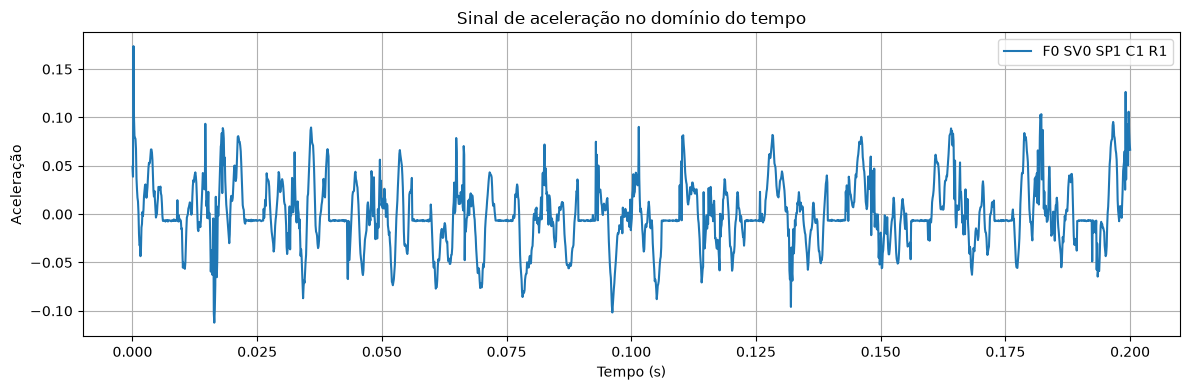

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [344]:
dataset_f0_small = filterDatasetByTimeInterval(dataset=dataset_f0,
                                               start_time=dataset_f0[0][2].min(),
                                               end_time=dataset_f0[0][2].min()+0.2)

FFT_analysis(signal=np.asarray(dataset_f0_small[0][0]).squeeze())

plotDataset(dataset_f0_small)

# EXPERIMENTO 2: CONDIÇÕES DE FALHA

Aqui, iremos experimentar com a condição de falha f1, com severidade máxima.

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F1_SV1_SP1_C1.mat` | Não-saudável | 3 | 1 | 1 | 1* | 600.000 | 10.000 Hz | 60 s | Mesma velocidade, canal, frequência e duração da referência saudável |

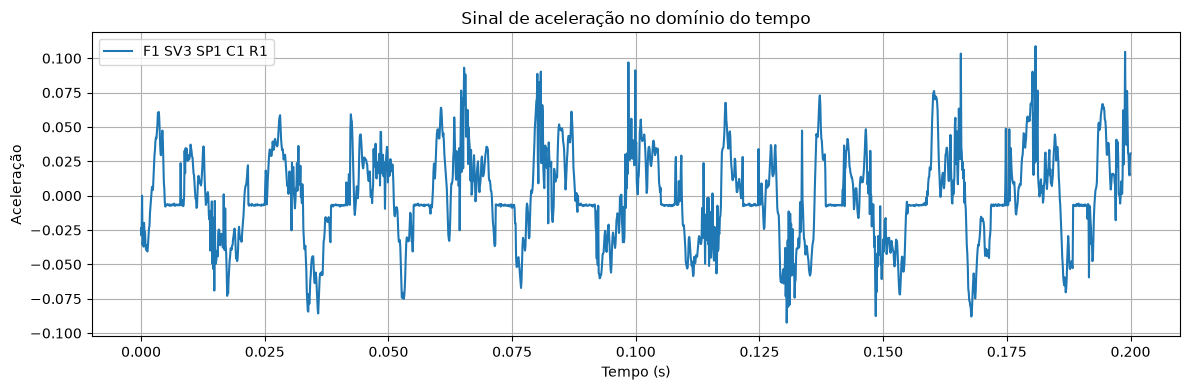

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [345]:
dataset_f1 = filterDataset(
    dataset=dataset,
    condition=1,
    severity=3,
    speed=1,
    channel=1,
    recording=1,
)

dataset_f1_small = filterDatasetByTimeInterval(dataset=dataset_f1,
                                               start_time=dataset_f1[0][2].min(),
                                               end_time=dataset_f1[0][2].min()+0.2)

FFT_analysis(signal=np.asarray(dataset_f1_small[0][0]).squeeze())

plotDataset(dataset_f1_small)

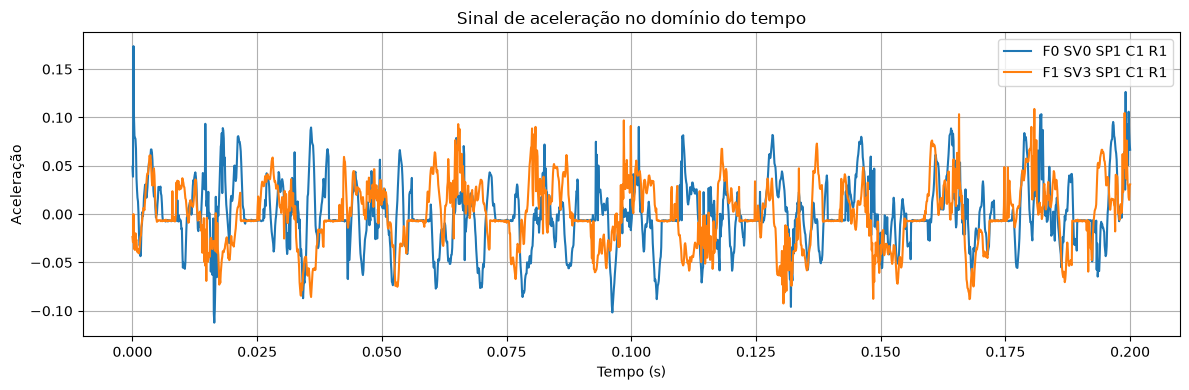

Drone saudável (F0):
  Número de amostras: 2001
  Resolução: 4.998 Hz
  Nyquist: 5000.0 Hz

Drone com falha (F1):
  Número de amostras: 2001
  Resolução: 4.998 Hz
  Nyquist: 5000.0 Hz



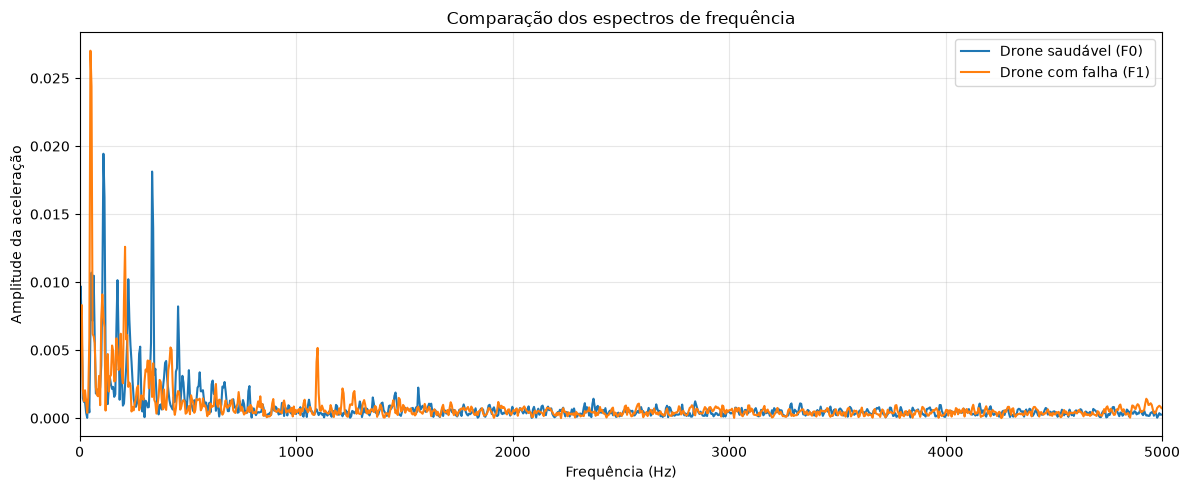

In [346]:
# show di bolations. Funcionou, agora queremos plotar os dois lado a lado. Para fazer isso, basta combinar os dois:
combined_ds = [dataset_f0_small[0], dataset_f1_small[0]]

plotDataset(combined_ds)

signal1 = np.asarray(combined_ds[0][0]).squeeze()
FFT_analysis(signal1)
signal2 = np.asarray(combined_ds[1][0]).squeeze()
FFT_analysis(signal2)

plot_fft_comparativa(dataset_f0_small, dataset_f1_small)

Comparando as duas formas de ver os dados, nota-se que, no tempo, é muito mais difícil diferenciar as duas situações, uma com falha e a outra não. 
Porém, ao levarmos os sinais para o domínio da frequência através da Transformada Rápida de Fourier (FFT) é percebível a distinção entre as duas num espectro menor até cerca de 2KHz, com o sinal de falha tendo picos muito incomuns e diferentes entre si, como visto nas ondas de cor azul.

# Extração de Informações

Nesta etapa, iremos extrair informações importantes para nossa análise, como calcular a frequeência dominante, a magnitude do pico dominante, potência do sinal, centróide e entropia espectral dos nossos sinais, para que com estes valores, possamos diferenciar situações distintas do sensoriamento do drone, e posteriormente, treinarmos um modelo de machine learning com essas informações, para que seja capaz de classificar situação/severidade a partir do sinal de entrada de um drone qualquer.


### Características espectrais

**Frequência dominante:** frequência correspondente à maior
amplitude do espectro, desconsiderando a componente DC.

$$
f_{dom} = f_{\arg\max_{k>0} A[k]}
$$

**Magnitude do pico dominante:** amplitude espectral
associada à frequência dominante.

$$
A_{pico} = \max_{k>0} A[k]
$$

**Potência em bandas:** soma da densidade espectral de
potência dentro de cada intervalo de frequência.

$$
P_B = \sum_{f_k \in B} PSD[k] \Delta f
$$

**Centroide espectral:** média ponderada das frequências
pelas amplitudes espectrais.

$$
C = \frac{\sum_k f_k A[k]}{\sum_k A[k]}
$$

**Entropia espectral:** medida da dispersão da energia
entre as componentes de frequência.

$$
H = -\sum_k p_k \log_2(p_k)
$$

com:

$$
p_k = \frac{A[k]^2}{\sum_j A[j]^2}
$$

Em todas as características baseadas em amplitude,
a componente DC foi retirada.


In [347]:
def frequencia_dominante(signal):
    fft_valores, frequencias = FFT_analysis(signal)
    indice_max = np.argmax(np.abs(fft_valores))
    frequencia_dominante = frequencias[indice_max]
    return frequencia_dominante

#Recebe-se os valores do espectro de frequência e as frequências correspondentes para cada sinal.
amplitudes_signal1, frequencias_signal1 = FFT_analysis(signal1)
amplitudes_signal2, frequencias_signal2 = FFT_analysis(signal2)

#Calcula-se o índice da frequência dominante para cada sinal.
frequencias_dominantes_signal1 = frequencia_dominante(signal1)
frequencias_dominantes_signal2 = frequencia_dominante(signal2)

print(f"Frequência dominante do sinal F1: {frequencias_dominantes_signal1:.2f} Hz")
print(f"Frequência dominante do sinal F2: {frequencias_dominantes_signal2:.2f} Hz")

Frequência dominante do sinal F1: 109.95 Hz
Frequência dominante do sinal F2: 49.98 Hz


In [348]:
def magnitude_pico(signal):
    amplitudes, _ = FFT_analysis(signal)
    magnitude_pico_dominante = np.max(np.abs(amplitudes))
    return magnitude_pico_dominante

#Calcula-se a magnitude do pico dominante para cada sinal.
magnitude_pico_dominante_signal1 = magnitude_pico(signal1)
magnitude_pico_dominante_signal2 = magnitude_pico(signal2)

print(f"Magnitudes dos picos dominantes: Sinal F1 = {magnitude_pico_dominante_signal1:.2f}, Sinal F2 = {magnitude_pico_dominante_signal2:.2f}")

Magnitudes dos picos dominantes: Sinal F1 = 0.02, Sinal F2 = 0.03


Segundo o teorema de Nyquist, a maior frequência que podemos analisar sem ambiguidade é:
$$
f_{\text{Nyquist}}=\frac{f_s}{2}
$$

Logo, com uma frequência padrão de 10KHz, podemos analisar apenas até cerca de 5KHz.

Portanto, para a análise ser rica, decidimos dividir em três bandas de frequência:
1. Baixas frequências em 0–500 Hz (Oscilações de menor frequência)
2. Médias frequências em 500-2000 Hz (Componentes intermediárias e possíveis harmônicos)
3. Altas frequências em 2000-5000 Hz (Componentes rápidas e conteúdo de alta frequência)

Utilizando a densidade espectral de potência (PSD) calculada a partir da FFT com janela de Hann.

Analisando os resultados sugerem uma possível redistribuição da potência espectral em direção às frequências mais elevadas na condição de falha.

In [349]:
BANDAS = {
    "P_0_500": (0, 500),
    "P_500_2000": (500, 2000),
    "P_2000_5000": (2000, 5000)
}

def potencia_media(signal, fs=10000):
    # Converter para vetor
    signal = np.asarray(signal, dtype=float).squeeze()
    N = len(signal)

    # Remover componente DC
    signal_sem_dc = signal - np.mean(signal)

    # Aplicar janela de Hann
    janela = np.hanning(N)
    sinal_janelado = signal_sem_dc * janela

    # Calcular FFT unilateral
    fft = np.fft.rfft(sinal_janelado)

    # Eixo de frequências
    frequencias = np.fft.rfftfreq(N, d=1/fs)

    # PSD normalizada pela energia da janela
    psd = np.abs(fft)**2 / (fs * np.sum(janela**2))

    # Converter PSD para espectro unilateral
    if N % 2 == 0:
        psd[1:-1] *= 2
    else:
        psd[1:] *= 2

    # Resolução espectral
    delta_f = fs / N

    # Calcular a potência em cada banda
    potencias = {}

    for nome, (f_min, f_max) in BANDAS.items():
        if f_max == fs / 2:
            mascara = (
                (frequencias >= f_min) &
                (frequencias <= f_max)
            )
        else:
            mascara = (
                (frequencias >= f_min) &
                (frequencias < f_max)
            )

        potencias[nome] = np.sum(psd[mascara]) * delta_f

    return potencias


#Calcula-se a potencia média do sinal no domínio da frequência para cada sinal.
potencia_s1 = potencia_media(signal)
potencia_s2 = potencia_media(signal2)


print(f"Potência média no domínio da frequência para o sinal F1:")
print(f"  Baixa frequência (0-500 Hz): {potencia_s1['P_0_500']}")
print(f"  Média frequência (500-2000 Hz): {potencia_s1['P_500_2000']}")
print(f"  Alta frequência (2000-5000 Hz): {potencia_s1['P_2000_5000']}\n")


print(f"Potência média no domínio da frequência para o sinal F2:")
print(f"  Baixa frequência (0-500 Hz): {potencia_s2['P_0_500']}")
print(f"  Média frequência (500-2000 Hz):   {potencia_s2['P_500_2000']}")
print(f"  Alta frequência (2000-5000 Hz): {potencia_s2['P_2000_5000']}")

Potência média no domínio da frequência para o sinal F1:
  Baixa frequência (0-500 Hz): 0.0009059039308974854
  Média frequência (500-2000 Hz): 7.587209194659637e-05
  Alta frequência (2000-5000 Hz): 4.7018868897195516e-05

Potência média no domínio da frequência para o sinal F2:
  Baixa frequência (0-500 Hz): 0.000904953879555652
  Média frequência (500-2000 Hz):   7.339343223304823e-05
  Alta frequência (2000-5000 Hz): 5.020622114566894e-05


In [350]:
def centroide_frequencia(signal):
    amplitudes, frequencias = FFT_analysis(signal)
    centroide = np.sum(frequencias * np.abs(amplitudes)) / np.sum(np.abs(amplitudes))
    return centroide

#Calcula-se o centroide do espectro de frequência para cada sinal.
centroide_signal1 = centroide_frequencia(signal1)
centroide_signal2 = centroide_frequencia(signal2)

print(f"""Centroide do espectro de frequência: 
    Sinal F0 = {centroide_signal1:.2f} Hz
    Sinal F1 = {centroide_signal2:.2f} Hz""")

Centroide do espectro de frequência: 
    Sinal F0 = 1457.91 Hz
    Sinal F1 = 1536.31 Hz


In [351]:
def entropia_espectral(signal):
    amplitudes, _ = FFT_analysis(signal)

    # Distribuição normalizada da energia espectral
    potencia = amplitudes[1:]**2
    total = np.sum(potencia)

    if total == 0:
        return 0.0

    probabilidades = potencia / total

    # Evitar log2(0) que daria problemas, então filtramos probabilidades > 0
    probabilidades = probabilidades[probabilidades > 0]

    entropia = -np.sum(probabilidades * np.log2(probabilidades))

    return entropia


entropia_espectral_signal1 = entropia_espectral(signal1)
entropia_espectral_signal2 = entropia_espectral(signal2)

print(f"""Entropia espectral: 
    Sinal F0 = {entropia_espectral_signal1:.2f}
    Sinal F1 = {entropia_espectral_signal2:.2f}""")

Entropia espectral: 
    Sinal F0 = 5.79
    Sinal F1 = 5.30


Com todas as funções definidas e demonstradas para os sinais de exemplo, vamos aplicar para todas as janelas dos datasets F0 e F1.

In [352]:

import pandas as pd

def extrair_features_janelas(dataset, fs=10000, duracao=0.2):
    resultados = []
    N_janela = int(round(fs * duracao))

    for record in dataset:
        sinal_completo = np.asarray(record[0]).squeeze()
        condition, severity, speed, channel, recording = record[3:8]

        for i, inicio in enumerate(
            range(0, len(sinal_completo) - N_janela + 1, N_janela)
        ):
            janela = sinal_completo[inicio:inicio + N_janela]

            potencias = potencia_media(janela, fs=fs)
            amplitudes, frequencias = FFT_analysis(janela, fs=fs)

            # Centroide pela amplitude espectral
            amplitudes_c = amplitudes.copy()
            amplitudes_c[0] = 0

            centroide = (
                np.sum(frequencias * amplitudes_c)
                / np.sum(amplitudes_c)
                if np.sum(amplitudes_c) > 0 else 0.0
            )

            resultados.append({
                "Condicao": f"F{condition}",
                "Severidade": severity,
                "Velocidade": speed,
                "Canal": channel,
                "Repeticao": recording,
                "Janela": i,
                "Tempo_inicio_s": inicio / fs,
                "Freq_dominante_Hz": frequencias[
                    np.argmax(amplitudes_c)
                ],
                "Magnitude_pico": np.max(amplitudes_c),
                **potencias,
                "Centroide_Hz": centroide,
                "Entropia_bits": entropia_espectral(janela)
            })

    return pd.DataFrame(resultados)


df_f0 = extrair_features_janelas(dataset_f0)
df_f1 = extrair_features_janelas(dataset_f1)

df_features = pd.concat([df_f0, df_f1], ignore_index=True)

display(df_features.head())
print(df_features.groupby("Condicao").size())

df_features.to_csv("features_dom_frequencia.csv", index=False)


,Condicao,Severidade,Velocidade,Canal,Repeticao,Janela,Tempo_inicio_s,Freq_dominante_Hz,Magnitude_pico,P_0_500,P_500_2000,P_2000_5000,Centroide_Hz,Entropia_bits
0,F0,0,1,1,1,0,0.0,110.0,0.019511,0.000904,0.000077,0.000047,1464.205122,5.785920
1,F0,0,1,1,1,1,0.2,55.0,0.034700,0.001918,0.000100,0.000068,1502.388104,4.682168
2,F0,0,1,1,1,2,0.4,55.0,0.045655,0.003673,0.000172,0.000148,1480.060844,4.647594
3,F0,0,1,1,1,3,0.6,55.0,0.040311,0.001996,0.000120,0.000104,1540.326052,4.850158
4,F0,0,1,1,1,4,0.8,55.0,0.049031,0.002270,0.000102,0.000101,1502.132967,4.639321


Condicao
F0    300
F1    300
dtype: int64


# Resultados visuais


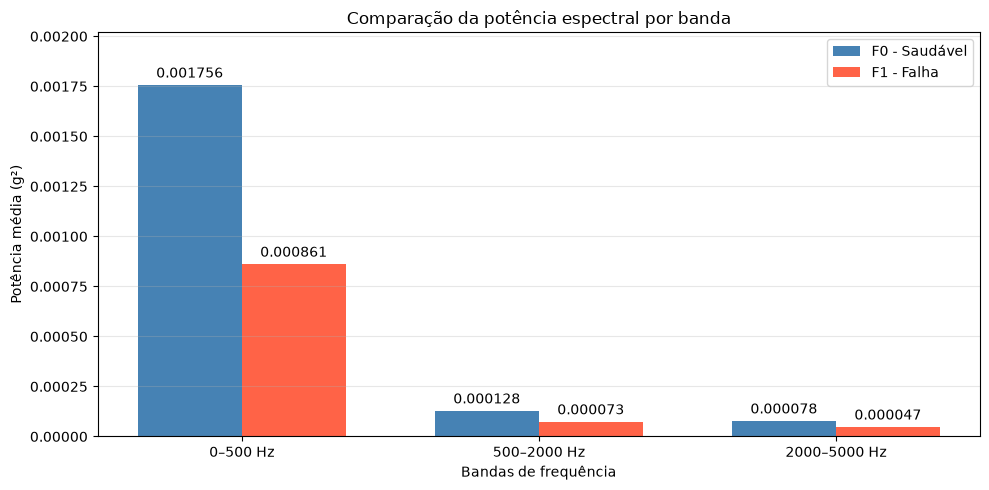

In [353]:
bandas = ["P_0_500", "P_500_2000", "P_2000_5000"]

# Média das potências por condição
medias = df_features.groupby("Condicao")[bandas].mean()

x = np.arange(len(bandas))
largura = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_f0 = ax.bar(
    x - largura/2,
    medias.loc["F0"],
    largura,
    label="F0 - Saudável",
    color="steelblue"
)

barras_f1 = ax.bar(
    x + largura/2,
    medias.loc["F1"],
    largura,
    label="F1 - Falha",
    color="tomato"
)

# Adicionar valores acima das barras
ax.bar_label(barras_f0, fmt="%.6f", padding=3)
ax.bar_label(barras_f1, fmt="%.6f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["0–500 Hz", "500–2000 Hz", "2000–5000 Hz"])

ax.set_ylabel("Potência média (g²)")
ax.set_xlabel("Bandas de frequência")
ax.set_title("Comparação da potência espectral por banda")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Espaço adicional para os valores
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

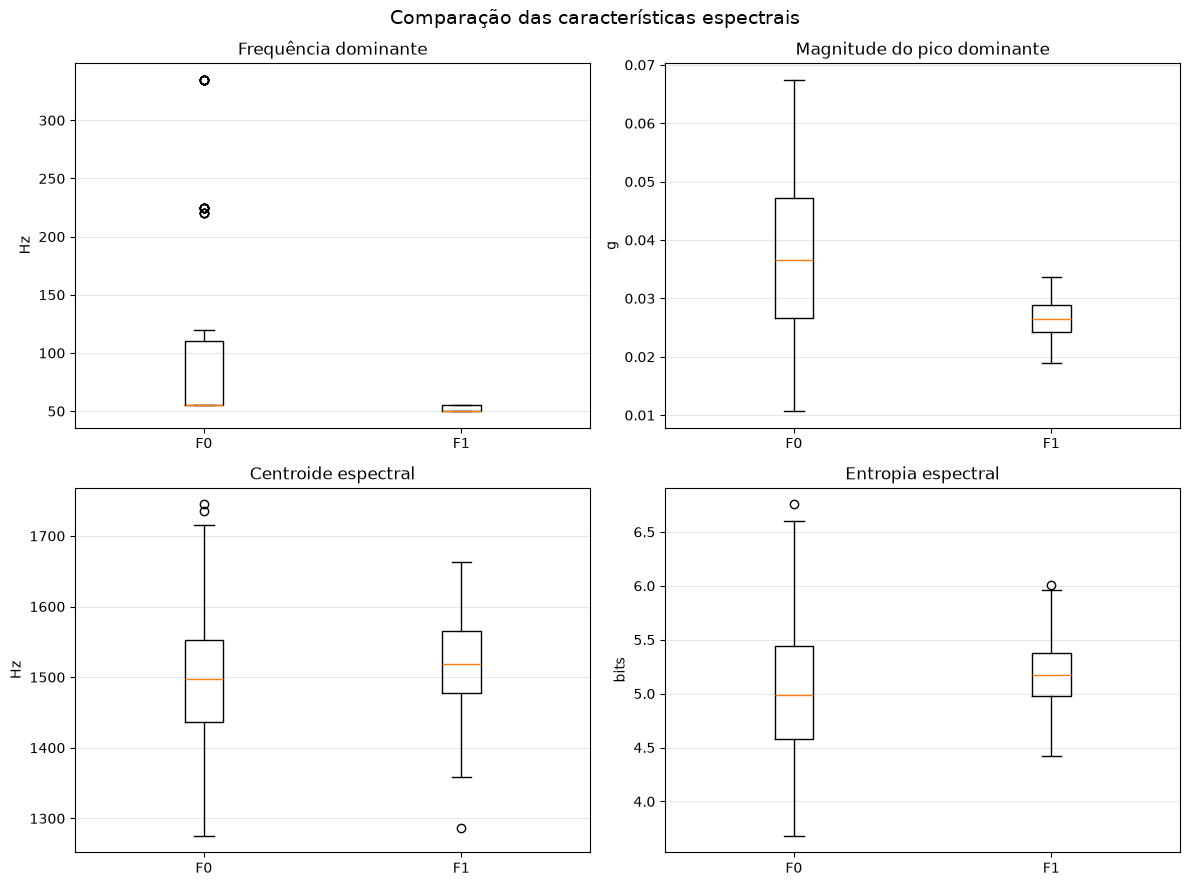

In [354]:
caracteristicas = [
    "Freq_dominante_Hz",
    "Magnitude_pico",
    "Centroide_Hz",
    "Entropia_bits"
]

titulos = [
    "Frequência dominante",
    "Magnitude do pico dominante",
    "Centroide espectral",
    "Entropia espectral"
]

unidades = ["Hz", "g", "Hz", "bits"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, coluna in enumerate(caracteristicas):
    dados = [
        df_features[df_features["Condicao"] == "F0"][coluna].dropna(),
        df_features[df_features["Condicao"] == "F1"][coluna].dropna()
    ]

    axes[i].boxplot(dados, tick_labels=["F0", "F1"])
    axes[i].set_title(titulos[i])
    axes[i].set_ylabel(unidades[i])
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle("Comparação das características espectrais",
             fontsize=14)

plt.tight_layout()
plt.show()


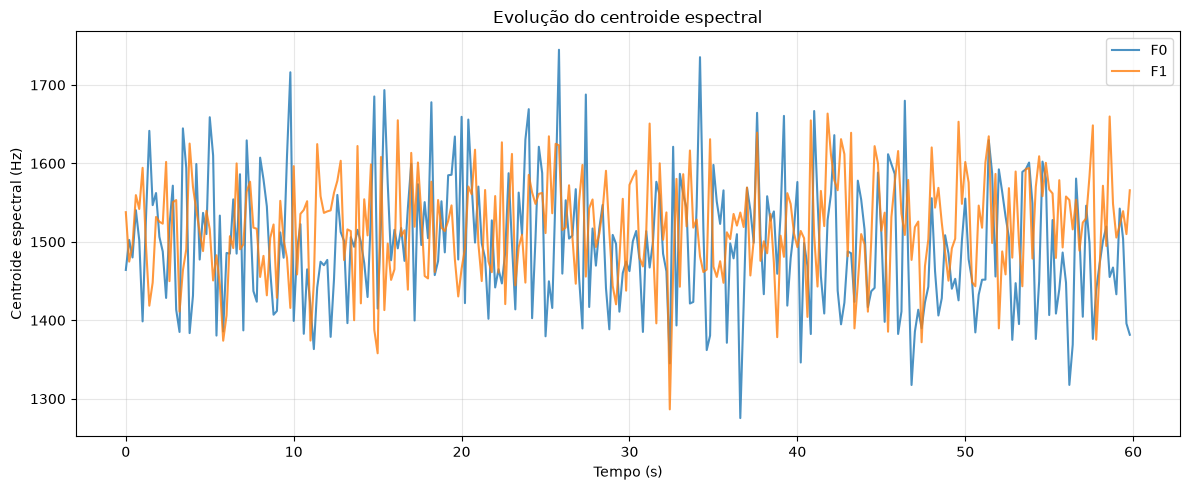

In [355]:
plt.figure(figsize=(12, 5))

for condicao, dados in df_features.groupby("Condicao"):
    dados = dados.sort_values("Tempo_inicio_s")

    plt.plot(
        dados["Tempo_inicio_s"],
        dados["Centroide_Hz"],
        label=condicao,
        alpha=0.8
    )

plt.title("Evolução do centroide espectral")
plt.xlabel("Tempo (s)")
plt.ylabel("Centroide espectral (Hz)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


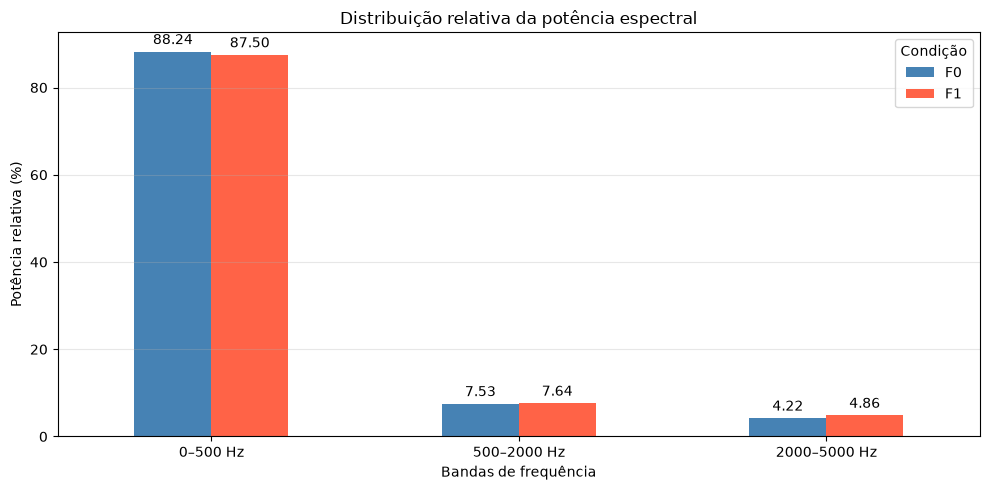

In [356]:
# Normalização percentual por janela
potencia_total = df_features[bandas].sum(axis=1)

df_percentual = df_features[["Condicao"]].copy()

for banda in bandas:
    df_percentual[banda] = np.where(
        potencia_total > 0,
        100 * df_features[banda] / potencia_total,
        np.nan
    )

# Média dos percentuais por condição
medias_percentuais = df_percentual.groupby("Condicao")[bandas].mean()

ax = medias_percentuais.T.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "tomato"]
)

ax.set_xticklabels(
    ["0–500 Hz", "500–2000 Hz", "2000–5000 Hz"],
    rotation=0
)

ax.set_title("Distribuição relativa da potência espectral")
ax.set_ylabel("Potência relativa (%)")
ax.set_xlabel("Bandas de frequência")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Condição")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.bar_label(ax.containers[1], fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


# Interpretação dos Espectros


In [357]:
from scipy.signal import find_peaks
import pandas as pd

def identificar_picos(signal, fs=10000, quantidade=5):
    amplitudes, frequencias = FFT_analysis(signal, fs)

    # Detectar máximos locais
    indices, _ = find_peaks(
        amplitudes,
        prominence=0.05 * np.max(amplitudes),
        distance=5
    )

    # Ordenar por amplitude decrescente
    indices = sorted(
        indices,
        key=lambda i: amplitudes[i],
        reverse=True
    )[:quantidade]

    return pd.DataFrame({
        "Frequencia_Hz": frequencias[indices],
        "Amplitude": amplitudes[indices]
    })


picos_f0 = identificar_picos(signal1)
picos_f1 = identificar_picos(signal2)

print("Principais picos - F0 (Saudável)")
display(picos_f0.round(5))

print("Principais picos - F1 (Falha)")
display(picos_f1.round(5))


Principais picos - F0 (Saudável)


,Frequencia_Hz,Amplitude
0,109.94503,0.01944
1,334.83258,0.01813
2,54.97251,0.01070
3,224.88756,0.01021
4,174.91254,0.01015


Principais picos - F1 (Falha)


,Frequencia_Hz,Amplitude
0,49.97501,0.02701
1,209.89505,0.01260
2,104.94753,0.00910
3,9.99500,0.00831
4,169.91504,0.00587


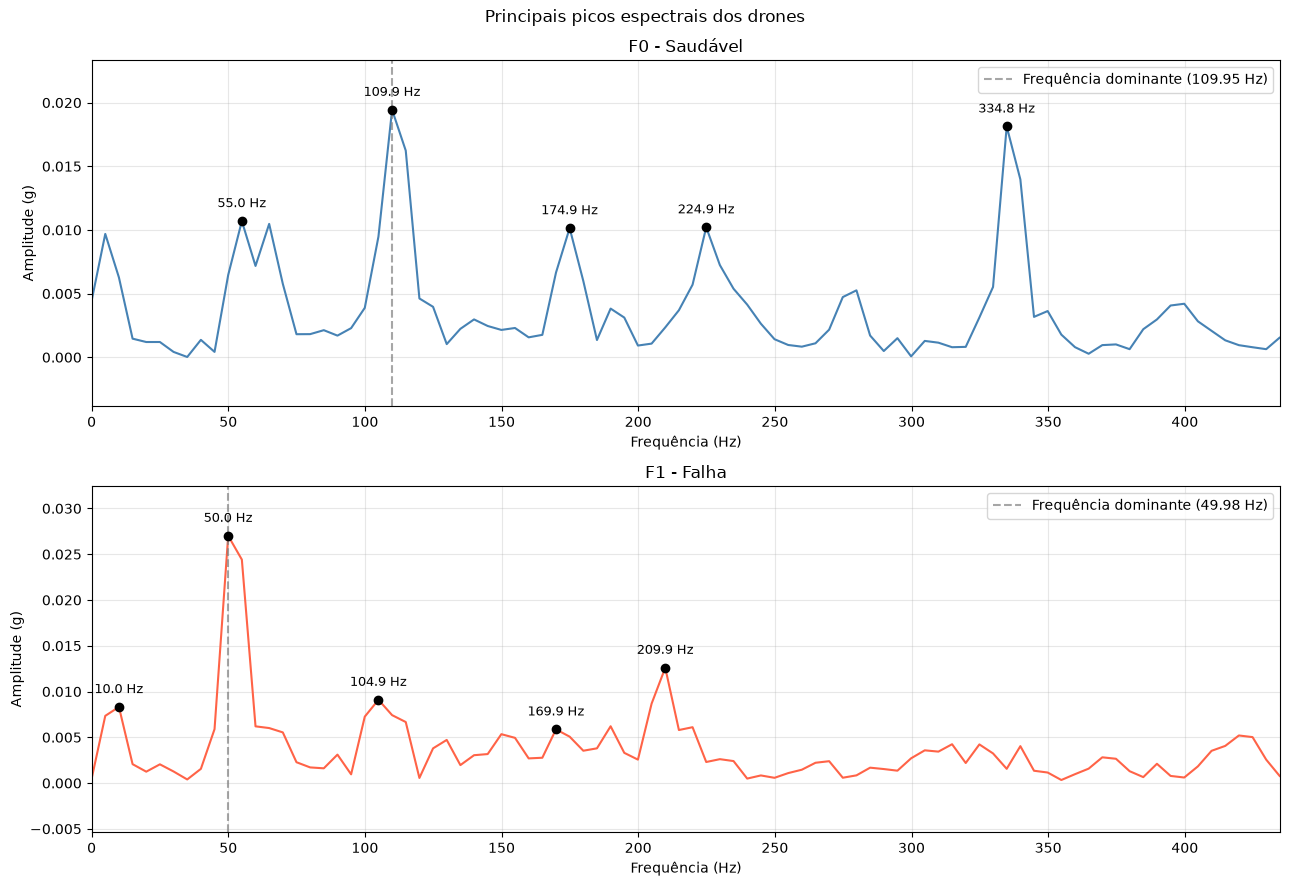

In [360]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

sinais = [
    (signal1, "F0 - Saudável", "steelblue"),
    (signal2, "F1 - Falha", "tomato")
]

for ax, (sinal, titulo, cor) in zip(axes, sinais):

    amplitudes, frequencias = FFT_analysis(sinal)
    freq_dominante = frequencia_dominante(sinal)

    picos = identificar_picos(sinal, quantidade=5)

    ax.plot(frequencias, amplitudes, color=cor)

    for _, pico in picos.iterrows():
        f = pico["Frequencia_Hz"]
        a = pico["Amplitude"]

        ax.scatter(f, a, color="black", zorder=3)

        ax.annotate(
            f"{f:.1f} Hz",
            xy=(f, a),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.axvline(freq_dominante, color="gray", linestyle="--", alpha=0.7,  label=f"Frequência dominante ({freq_dominante:.2f} Hz)")
    ax.set_title(titulo)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Amplitude (g)")
    ax.set_xlim(0, max(picos_f1["Frequencia_Hz"].max(), picos_f0["Frequencia_Hz"].max()) + 100)
    ax.margins(y=0.20)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

plt.suptitle("Principais picos espectrais dos drones")
plt.tight_layout()
plt.show()


### Interpretação dos espectros de frequência

A análise dos espectros de frequência dos drones saudável (F0) e com falha (F1) revelou diferenças na distribuição das componentes espectrais, mesmo quando os respectivos sinais no domínio temporal apresentam comportamentos oscilatórios visualmente parecidos.

Na janela inicial analisada, o drone saudável apresentou frequência dominante de aproximadamente **109,95 Hz**, enquanto o drone com falha apresentou frequência dominante próxima de **49,98 Hz**. As magnitudes dos respectivos picos dominantes foram aproximadamente 0,02 e 0,03, indicando diferenças tanto na localização quanto na intensidade da componente espectral predominante.

O centroide espectral também apresentou diferenças, passando de 1.457,91 Hz na condição saudável para 1.536,31 Hz na condição de falha. Esse aumento indica maior contribuição relativa de componentes de frequência mais elevada para a distribuição de amplitudes espectrais do sinal F1.

Em relação à entropia espectral, foram obtidos 5,79 bits para F0 e 5,30 bits para F1, sugerindo uma distribuição espectral relativamente mais concentrada no sinal com falha, considerando a janela analisada.

A representação no domínio da frequência fornece informações que não são imediatamente perceptíveis no gráfico temporal, pois permite distinguir as componentes de frequência que, no tempo, aparecem sobrepostas. Dessa forma, torna-se possível identificar picos predominantes, comparar suas amplitudes e avaliar mudanças na distribuição espectral entre as condições.

Embora essas diferenças possam ser relevantes para a caracterização dos estados operacionais, não é possível associar individualmente cada pico a uma causa física específica sem informações adicionais sobre o funcionamento e as características mecânicas do sistema.

Portanto, os resultados demonstram bem a utilidade da análise em frequência como ferramenta complementar à análise temporal para identificar diferenças no comportamento vibracional dos drones.